In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv(r"C:\Users\vidit\Downloads\Indoor Fire Dataset with Distributed Multi-Sensor Nodes_Industrial Hall.csv")

In [3]:
df.head()

,Date,Sensor_ID,CO2_Room,scenario_label,progress_label,experiment_number,H2_Room,PM05_Room,PM100_Room,PM10_Room,...,PM_Total_Room,VOC_Room_RAW,Valid_Experiment,fire,nuisance,Temperature_Room,Humidity_Room,CO_Room,anomaly_label,anomaly_scenario
0,2023-07-10 09:30:27+02:00,sensornode0009,926.0,Background,Ignition,0.0,0.0,22.0,0.0,3.0,...,25.0,0.1,1.0,0.0,0.0,28.2,47.0,0.54,0.0,NaN
1,2023-07-10 09:30:27+02:00,sensornode0008,821.0,Background,Ignition,0.0,0.0,23.0,0.0,3.0,...,26.0,0.2,1.0,0.0,0.0,28.2,48.1,0.31,0.0,NaN
2,2023-07-10 09:30:30+02:00,sensornode0010,599.0,Background,Ignition,0.0,0.2,19.0,0.0,2.0,...,22.0,0.0,1.0,0.0,0.0,27.7,48.4,0.10,0.0,NaN
3,2023-07-10 09:30:32+02:00,sensornode0012,919.0,Background,Ignition,0.0,0.1,21.0,0.0,3.0,...,24.0,0.0,1.0,0.0,0.0,27.3,47.9,0.13,0.0,NaN
4,2023-07-10 09:30:33+02:00,sensornode0015,737.0,Background,Ignition,0.0,0.1,22.0,0.0,3.0,...,25.0,0.0,1.0,0.0,0.0,27.0,49.4,0.00,0.0,NaN


In [4]:
df.tail()

,Date,Sensor_ID,CO2_Room,scenario_label,progress_label,experiment_number,H2_Room,PM05_Room,PM100_Room,PM10_Room,...,PM_Total_Room,VOC_Room_RAW,Valid_Experiment,fire,nuisance,Temperature_Room,Humidity_Room,CO_Room,anomaly_label,anomaly_scenario
248497,2023-07-13 14:42:59+02:00,sensornode0013,624.0,Background,NaN,0.0,0.4,12.0,0.0,1.0,...,14.0,0.0,1.0,0.0,0.0,26.1,42.7,0.0,0.0,NaN
248498,2023-07-13 14:43:02+02:00,sensornode0012,855.0,Background,NaN,0.0,0.4,14.0,0.0,2.0,...,16.0,0.0,1.0,0.0,0.0,27.0,41.1,0.0,0.0,NaN
248499,2023-07-13 14:43:03+02:00,sensornode0015,687.0,Background,NaN,0.0,0.5,14.0,0.0,2.0,...,17.0,0.0,1.0,0.0,0.0,25.7,45.1,0.0,0.0,NaN
248500,2023-07-13 14:43:09+02:00,sensornode0013,578.0,Background,NaN,0.0,0.4,12.0,0.0,1.0,...,14.0,0.0,1.0,0.0,0.0,26.1,42.7,0.0,0.0,NaN
248501,2023-07-13 14:43:12+02:00,sensornode0012,856.0,Background,NaN,0.0,0.4,13.0,0.0,1.0,...,15.0,0.0,1.0,0.0,0.0,27.0,41.2,0.0,0.0,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 248502 entries, 0 to 248501
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Date                  248502 non-null  object 
 1   Sensor_ID             248502 non-null  object 
 2   CO2_Room              248502 non-null  float64
 3   scenario_label        248502 non-null  object 
 4   progress_label        246712 non-null  object 
 5   experiment_number     248502 non-null  float64
 6   H2_Room               248502 non-null  float64
 7   PM05_Room             248502 non-null  float64
 8   PM100_Room            248502 non-null  float64
 9   PM10_Room             248502 non-null  float64
 10  PM25_Room             248502 non-null  float64
 11  PM40_Room             248502 non-null  float64
 12  PM_Room_Typical_Size  248502 non-null  float64
 13  PM_Total_Room         248502 non-null  float64
 14  VOC_Room_RAW          248502 non-null  float64
 15  

In [6]:
df.describe()

,CO2_Room,experiment_number,H2_Room,PM05_Room,PM100_Room,PM10_Room,PM25_Room,PM40_Room,PM_Room_Typical_Size,PM_Total_Room,VOC_Room_RAW,Valid_Experiment,fire,nuisance,Temperature_Room,Humidity_Room,CO_Room,anomaly_label,anomaly_scenario
count,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.000000,248502.0,248502.000000,248502.000000,248502.000000,248502.000000,248502.00000,248502.00000,40565.000000
mean,639.862420,0.426789,1.260386,145.877063,0.019344,21.611102,0.847780,0.101705,0.477424,169.151146,1.307157,1.0,0.110748,0.038869,28.673868,42.729748,0.58100,0.16581,16.715173
std,173.034775,1.186904,1.456919,707.137390,0.559562,111.602642,13.797021,2.414040,0.057265,824.702789,1.392570,0.0,0.313820,0.193283,2.628347,5.492144,2.65074,0.37191,8.961976
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,20.400000,32.800000,0.00000,0.00000,1.000000
25%,530.000000,0.000000,0.200000,14.000000,0.000000,2.000000,0.000000,0.000000,0.440000,17.000000,0.300000,1.0,0.000000,0.000000,26.900000,38.600000,0.00000,0.00000,8.000000
50%,639.000000,0.000000,0.800000,19.000000,0.000000,2.000000,0.000000,0.000000,0.470000,22.000000,0.900000,1.0,0.000000,0.000000,28.800000,42.700000,0.18000,0.00000,19.000000
75%,760.000000,0.000000,1.600000,37.000000,0.000000,5.000000,0.000000,0.000000,0.500000,43.000000,1.900000,1.0,0.000000,0.000000,30.500000,46.500000,0.64000,0.00000,24.000000
max,2628.000000,7.000000,49.200000,28685.000000,127.000000,7447.000000,2654.000000,498.000000,1.230000,34168.000000,36.200000,1.0,1.000000,1.000000,35.200000,69.800000,216.81000,1.00000,32.000000


In [7]:
df.columns

Index(['Date', 'Sensor_ID', 'CO2_Room', 'scenario_label', 'progress_label',
       'experiment_number', 'H2_Room', 'PM05_Room', 'PM100_Room', 'PM10_Room',
       'PM25_Room', 'PM40_Room', 'PM_Room_Typical_Size', 'PM_Total_Room',
       'VOC_Room_RAW', 'Valid_Experiment', 'fire', 'nuisance',
       'Temperature_Room', 'Humidity_Room', 'CO_Room', 'anomaly_label',
       'anomaly_scenario'],
      dtype='object')

In [8]:
df.shape

(248502, 23)

In [9]:
df.isnull().sum()

Date                         0
Sensor_ID                    0
CO2_Room                     0
scenario_label               0
progress_label            1790
experiment_number            0
H2_Room                      0
PM05_Room                    0
PM100_Room                   0
PM10_Room                    0
PM25_Room                    0
PM40_Room                    0
PM_Room_Typical_Size         0
PM_Total_Room                0
VOC_Room_RAW                 0
Valid_Experiment             0
fire                         0
nuisance                     0
Temperature_Room             0
Humidity_Room                0
CO_Room                      0
anomaly_label                0
anomaly_scenario        207937
dtype: int64

In [10]:
df.anomaly_scenario.unique()

array([nan,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
       26., 27., 28., 29., 30., 31., 32.])

In [11]:
df['anomaly_label'].value_counts()

anomaly_label
0.0    207298
1.0     41204
Name: count, dtype: int64

In [12]:
df['anomaly_scenario'].value_counts()

anomaly_scenario
21.0    4051
23.0    2281
27.0    2168
11.0    2159
2.0     2049
8.0     2035
25.0    1746
18.0    1722
29.0    1710
30.0    1704
20.0    1689
15.0    1620
4.0     1562
9.0     1526
22.0    1471
5.0     1417
24.0    1168
7.0     1035
3.0      918
1.0      765
17.0     747
19.0     619
6.0      616
10.0     567
14.0     553
31.0     540
26.0     528
16.0     496
28.0     479
12.0     357
32.0     266
13.0       1
Name: count, dtype: int64

In [13]:
df['scenario_label'].value_counts()

scenario_label
Background          207937
Wood                 13309
Candles               6652
Lunts                 5481
Green_Waste           2807
Ethanol               2661
Deodorant             2104
Cable                 2079
Exhaust               2042
CO                    1363
Smoke                 1261
Welding                540
Abrasive_Cutting       266
Name: count, dtype: int64

In [14]:
df['progress_label'].value_counts(dropna=False)

progress_label
Outgasing       168867
Smoldering       61264
Ignition          7931
Flaming           5127
Short_Cicuit      3346
NaN               1790
Swirling           177
Name: count, dtype: int64

In [15]:
df['CO2_Room'].describe()

count    248502.000000
mean        639.862420
std         173.034775
min           0.000000
25%         530.000000
50%         639.000000
75%         760.000000
max        2628.000000
Name: CO2_Room, dtype: float64

In [16]:
(df['CO2_Room'] == 0).sum()

np.int64(11)

In [17]:
df['CO2_Room'].quantile([0.01, 0.05, 0.95, 0.99])

0.01    192.0
0.05    319.0
0.95    908.0
0.99    954.0
Name: CO2_Room, dtype: float64

In [18]:
df.groupby('anomaly_label')['CO2_Room'].mean()

anomaly_label
0.0    638.393680
1.0    647.251675
Name: CO2_Room, dtype: float64

In [19]:
df[[
    'CO2_Room',
    'H2_Room',
    'PM05_Room',
    'PM100_Room',
    'PM10_Room',
    'PM25_Room',
    'PM40_Room',
    'PM_Room_Typical_Size',
    'PM_Total_Room',
    'VOC_Room_RAW',
    'Temperature_Room',
    'Humidity_Room',
    'CO_Room'
]].describe().T

,count,mean,std,min,25%,50%,75%,max
CO2_Room,248502.0,639.862420,173.034775,0.0,530.00,639.00,760.00,2628.00
H2_Room,248502.0,1.260386,1.456919,0.0,0.20,0.80,1.60,49.20
PM05_Room,248502.0,145.877063,707.137390,0.0,14.00,19.00,37.00,28685.00
PM100_Room,248502.0,0.019344,0.559562,0.0,0.00,0.00,0.00,127.00
PM10_Room,248502.0,21.611102,111.602642,0.0,2.00,2.00,5.00,7447.00
PM25_Room,248502.0,0.847780,13.797021,0.0,0.00,0.00,0.00,2654.00
PM40_Room,248502.0,0.101705,2.414040,0.0,0.00,0.00,0.00,498.00
PM_Room_Typical_Size,248502.0,0.477424,0.057265,0.0,0.44,0.47,0.50,1.23
PM_Total_Room,248502.0,169.151146,824.702789,0.0,17.00,22.00,43.00,34168.00
VOC_Room_RAW,248502.0,1.307157,1.392570,0.0,0.30,0.90,1.90,36.20


In [20]:
pm_cols = [
    'PM05_Room',
    'PM100_Room',
    'PM10_Room',
    'PM25_Room',
    'PM40_Room',
    'PM_Room_Typical_Size',
    'PM_Total_Room'
]

(df[pm_cols] == 0).sum()

PM05_Room                    1
PM100_Room              246037
PM10_Room                    8
PM25_Room               230061
PM40_Room               242506
PM_Room_Typical_Size         1
PM_Total_Room                1
dtype: int64

In [21]:
df.groupby('anomaly_label')[['PM100_Room', 'PM25_Room', 'PM40_Room']].apply(
    lambda x: (x == 0).sum()
)

,PM100_Room,PM25_Room,PM40_Room
anomaly_label,,,
0.0,207297,205347,207297
1.0,38740,24714,35209


In [22]:
df.groupby('anomaly_label')[
    ['CO2_Room', 'H2_Room', 'VOC_Room_RAW', 'CO_Room',
     'Temperature_Room', 'Humidity_Room',
     'PM05_Room', 'PM10_Room', 'PM_Total_Room',
     'PM_Room_Typical_Size']
].mean()

,CO2_Room,H2_Room,VOC_Room_RAW,CO_Room,Temperature_Room,Humidity_Room,PM05_Room,PM10_Room,PM_Total_Room,PM_Room_Typical_Size
anomaly_label,,,,,,,,,,
0.0,638.393680,1.368523,1.175749,0.392949,28.608396,42.790295,28.612611,3.746167,32.975711,0.470407
1.0,647.251675,0.716346,1.968272,1.527086,29.003257,42.425133,735.836448,111.489880,854.251990,0.512727


In [23]:
df.groupby('anomaly_label')[
    ['CO2_Room', 'H2_Room', 'VOC_Room_RAW', 'CO_Room',
     'Temperature_Room', 'Humidity_Room',
     'PM05_Room', 'PM10_Room', 'PM_Total_Room',
     'PM_Room_Typical_Size']
].median()

,CO2_Room,H2_Room,VOC_Room_RAW,CO_Room,Temperature_Room,Humidity_Room,PM05_Room,PM10_Room,PM_Total_Room,PM_Room_Typical_Size
anomaly_label,,,,,,,,,,
0.0,636.0,1.0,0.9,0.16,28.7,42.7,17.0,2.0,20.0,0.46
1.0,658.0,0.4,1.3,0.35,28.9,42.7,96.0,13.0,110.0,0.49


In [24]:
df.groupby('anomaly_label')[
    ['CO2_Room', 'H2_Room', 'VOC_Room_RAW', 'CO_Room',
     'Temperature_Room', 'Humidity_Room',
     'PM05_Room', 'PM10_Room', 'PM_Total_Room',
     'PM_Room_Typical_Size']
].std()

,CO2_Room,H2_Room,VOC_Room_RAW,CO_Room,Temperature_Room,Humidity_Room,PM05_Room,PM10_Room,PM_Total_Room,PM_Room_Typical_Size
anomaly_label,,,,,,,,,,
0.0,171.480763,1.412473,1.099681,0.579453,2.647154,5.522513,64.294655,9.286391,73.773128,0.048705
1.0,180.471239,1.552248,2.255619,6.294048,2.505823,5.326375,1605.549512,254.952458,1874.015496,0.079680


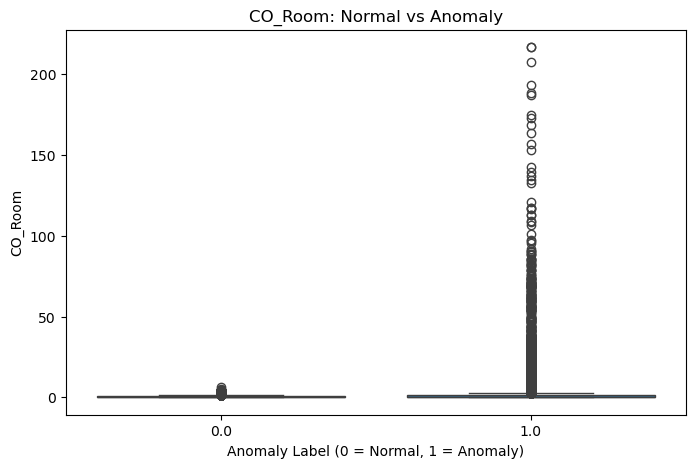

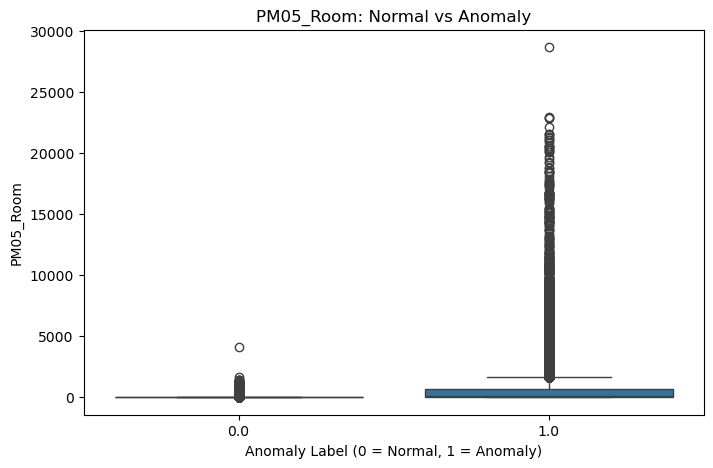

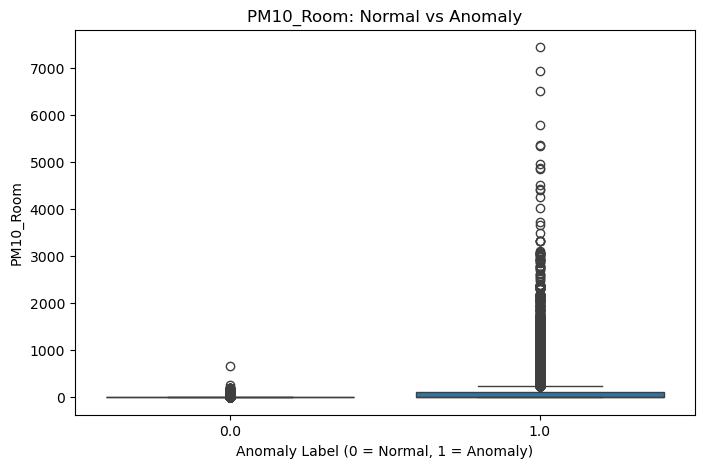

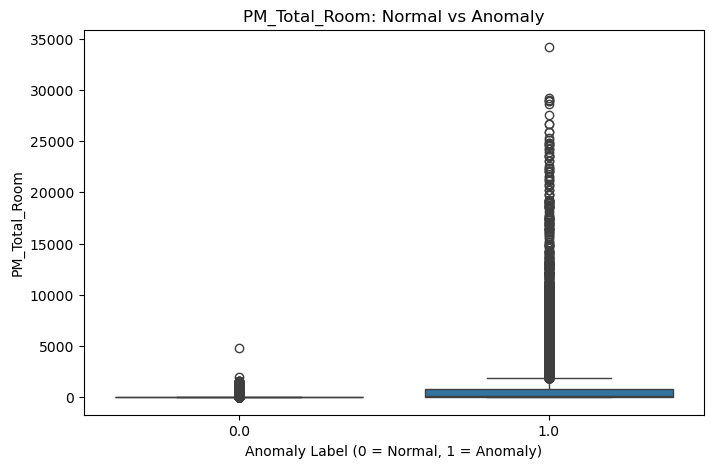

In [25]:
sensors = ['CO_Room', 'PM05_Room', 'PM10_Room', 'PM_Total_Room']

for sensor in sensors:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='anomaly_label', y=sensor, data=df)
    plt.title(f'{sensor}: Normal vs Anomaly')
    plt.xlabel('Anomaly Label (0 = Normal, 1 = Anomaly)')
    plt.ylabel(sensor)
    plt.show()

In [26]:
df['Date'].head()

0    2023-07-10 09:30:27+02:00
1    2023-07-10 09:30:27+02:00
2    2023-07-10 09:30:30+02:00
3    2023-07-10 09:30:32+02:00
4    2023-07-10 09:30:33+02:00
Name: Date, dtype: object

In [27]:
df['Date'].nunique()

193298

In [28]:
df['Sensor_ID'].value_counts()

Sensor_ID
sensornode0015    27622
sensornode0013    27622
sensornode0012    27622
sensornode0007    27613
sensornode0006    27612
sensornode0008    27604
sensornode0009    27603
sensornode0010    27602
sensornode0011    27602
Name: count, dtype: int64

In [29]:
df['experiment_number'].value_counts()

experiment_number
0.0    207938
1.0     14010
2.0      9346
3.0      6670
4.0      4920
6.0      2168
5.0      1746
7.0      1704
Name: count, dtype: int64

In [30]:
df[['Valid_Experiment', 'fire', 'nuisance']].value_counts(dropna=False)

Valid_Experiment  fire  nuisance
1.0               0.0   0.0         211322
                  1.0   0.0          27521
                  0.0   1.0           9659
Name: count, dtype: int64

In [31]:
pd.crosstab(df['fire'], df['anomaly_label'])

anomaly_label,0.0,1.0
fire,,
0.0,207298,13683
1.0,0,27521


In [32]:
pd.crosstab(df['nuisance'], df['anomaly_label'])

anomaly_label,0.0,1.0
nuisance,,
0.0,207298,31545
1.0,0,9659


In [33]:
pd.crosstab(df['anomaly_scenario'].isna(), df['anomaly_label'])

anomaly_label,0.0,1.0
anomaly_scenario,,
False,0,40565
True,207298,639


In [34]:
sensor_cols = [
    'CO2_Room', 'H2_Room', 'VOC_Room_RAW', 'CO_Room',
    'PM05_Room', 'PM100_Room', 'PM10_Room', 'PM25_Room',
    'PM40_Room', 'PM_Room_Typical_Size', 'PM_Total_Room',
    'Temperature_Room', 'Humidity_Room'
]

df[sensor_cols].nunique()

CO2_Room                1025
H2_Room                  193
VOC_Room_RAW             230
CO_Room                 1893
PM05_Room               4853
PM100_Room                32
PM10_Room               1365
PM25_Room                239
PM40_Room                 86
PM_Room_Typical_Size      81
PM_Total_Room           5317
Temperature_Room         149
Humidity_Room            359
dtype: int64

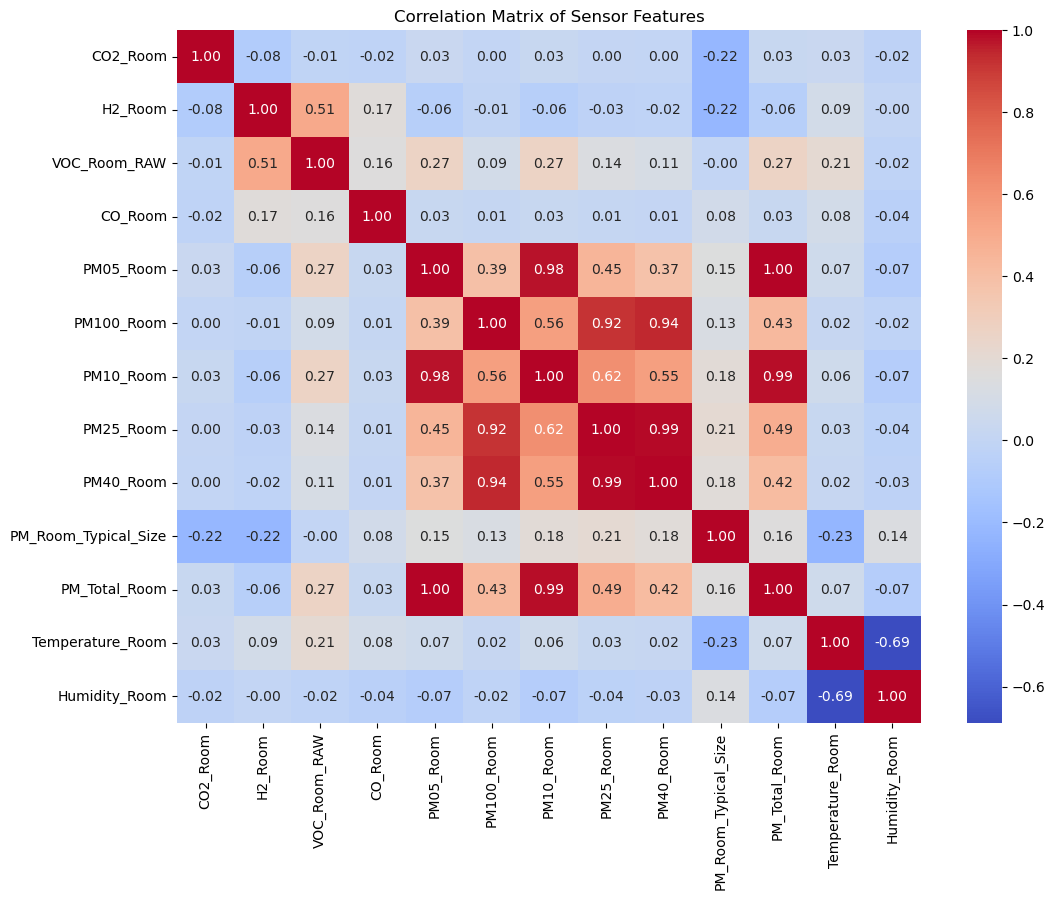

In [35]:
sensor_cols = [
    'CO2_Room',
    'H2_Room',
    'VOC_Room_RAW',
    'CO_Room',
    'PM05_Room',
    'PM100_Room',
    'PM10_Room',
    'PM25_Room',
    'PM40_Room',
    'PM_Room_Typical_Size',
    'PM_Total_Room',
    'Temperature_Room',
    'Humidity_Room'
]

corr = df[sensor_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Sensor Features')
plt.show()

In [36]:
sensor_cols = [
    'CO2_Room',
    'H2_Room',
    'VOC_Room_RAW',
    'CO_Room',
    'PM05_Room',
    'PM100_Room',
    'PM10_Room',
    'PM25_Room',
    'PM40_Room',
    'PM_Room_Typical_Size',
    'PM_Total_Room',
    'Temperature_Room',
    'Humidity_Room'
]

skewness = df[sensor_cols].skew().sort_values(ascending=False)

print(skewness)

PM100_Room              146.408682
PM40_Room               116.657085
PM25_Room               100.486764
CO_Room                  33.437553
PM10_Room                15.923919
PM_Total_Room            12.372105
PM05_Room                11.961925
VOC_Room_RAW              3.261309
H2_Room                   2.676959
PM_Room_Typical_Size      1.814122
Humidity_Room             0.384377
Temperature_Room         -0.071806
CO2_Room                 -0.240572
dtype: float64


In [37]:
df_transformed = df.copy()

In [38]:
skewed_cols = [
    'PM100_Room',
    'PM40_Room',
    'PM25_Room',
    'CO_Room',
    'PM10_Room',
    'PM_Total_Room',
    'PM05_Room',
    'VOC_Room_RAW',
    'H2_Room',
    'PM_Room_Typical_Size'
]

df_transformed[skewed_cols] = np.log1p(df_transformed[skewed_cols])

In [39]:
print(df_transformed[skewed_cols].skew().sort_values(ascending=False))

PM100_Room              15.088398
PM40_Room                9.920563
PM25_Room                5.018464
CO_Room                  2.642102
PM10_Room                2.501480
PM05_Room                2.442688
PM_Total_Room            2.431668
PM_Room_Typical_Size     1.495847
H2_Room                  0.571014
VOC_Room_RAW             0.479958
dtype: float64


In [40]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_scaled = scaler.fit_transform(df_transformed[sensor_cols])

In [41]:
print(X_scaled.shape)

(248502, 13)


C:\Users\vidit\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\vidit\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\vidit\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vidit\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

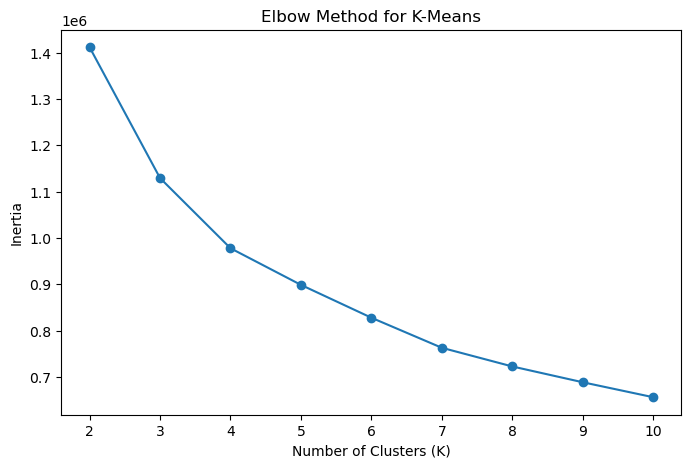

In [42]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.show()

In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Take a sample for Silhouette Score
sample_size = 10000

X_sample = X_scaled[:sample_size]

silhouette_scores = {}

for k in [3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_sample)

    score = silhouette_score(X_sample, labels)
    silhouette_scores[k] = score

    print(f"K = {k} → Silhouette Score = {score:.4f}")

K = 3 → Silhouette Score = 0.3021
K = 4 → Silhouette Score = 0.2713


In [44]:
from sklearn.cluster import KMeans

# Final K-Means model
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model on the complete scaled dataset
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to the transformed dataframe
df_transformed['cluster'] = cluster_labels

print(df_transformed['cluster'].value_counts().sort_index())

cluster
0    162697
1     17320
2     68485
Name: count, dtype: int64


In [45]:
import pandas as pd

cluster_anomaly = pd.crosstab(
    df_transformed['cluster'],
    df_transformed['anomaly_label']
)

print(cluster_anomaly)

anomaly_label     0.0    1.0
cluster                     
0              156099   6598
1                1599  15721
2               49600  18885


In [46]:
cluster_anomaly_pct = pd.crosstab(
    df_transformed['cluster'],
    df_transformed['anomaly_label'],
    normalize='index'
) * 100

print(cluster_anomaly_pct.round(2))

anomaly_label    0.0    1.0
cluster                    
0              95.94   4.06
1               9.23  90.77
2              72.42  27.58


In [47]:
cluster_profile = df_transformed.groupby('cluster')[sensor_cols].mean()

print(cluster_profile.round(2))

         CO2_Room  H2_Room  VOC_Room_RAW  CO_Room  PM05_Room  PM100_Room  \
cluster                                                                    
0          635.28     0.72          0.69     0.22       2.82        0.00   
1          649.83     0.44          1.14     0.45       6.96        0.13   
2          648.22     0.56          0.61     0.49       3.89        0.00   

         PM10_Room  PM25_Room  PM40_Room  PM_Room_Typical_Size  PM_Total_Room  \
cluster                                                                         
0             1.05       0.00       0.00                  0.38           2.96   
1             5.09       1.74       0.41                  0.42           7.12   
2             2.04       0.03       0.00                  0.40           4.03   

         Temperature_Room  Humidity_Room  
cluster                                   
0                   27.78          44.05  
1                   29.32          41.62  
2                   30.63          39.86 

In [51]:
print(sensor_cols)

['CO2_Room', 'H2_Room', 'VOC_Room_RAW', 'CO_Room', 'PM05_Room', 'PM100_Room', 'PM10_Room', 'PM25_Room', 'PM40_Room', 'PM_Room_Typical_Size', 'PM_Total_Room', 'Temperature_Room', 'Humidity_Room']


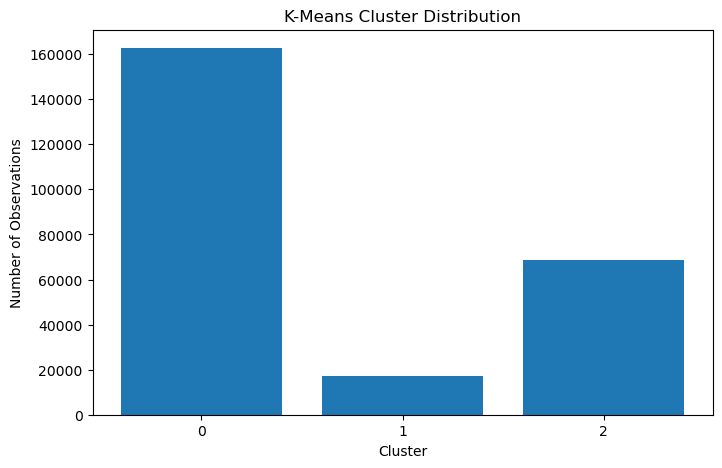

In [52]:
import matplotlib.pyplot as plt

cluster_counts = df_transformed['cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)

plt.xlabel('Cluster')
plt.ylabel('Number of Observations')
plt.title('K-Means Cluster Distribution')

plt.show()

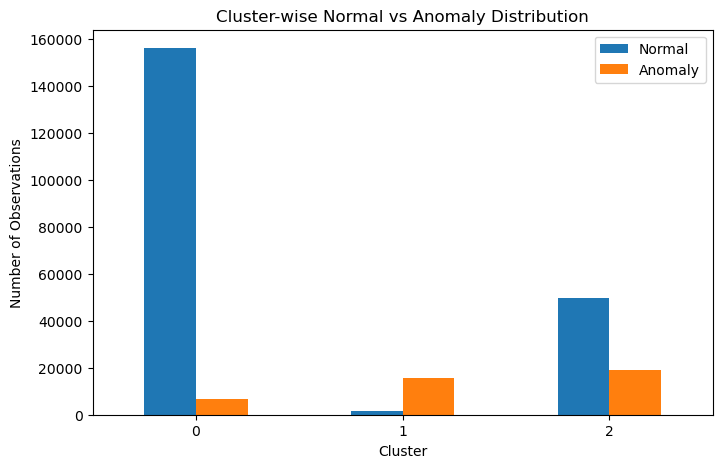

In [53]:
cluster_anomaly_counts = pd.crosstab(
    df_transformed['cluster'],
    df_transformed['anomaly_label']
)

cluster_anomaly_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Cluster')
plt.ylabel('Number of Observations')
plt.title('Cluster-wise Normal vs Anomaly Distribution')
plt.xticks(rotation=0)
plt.legend(['Normal', 'Anomaly'])

plt.show()

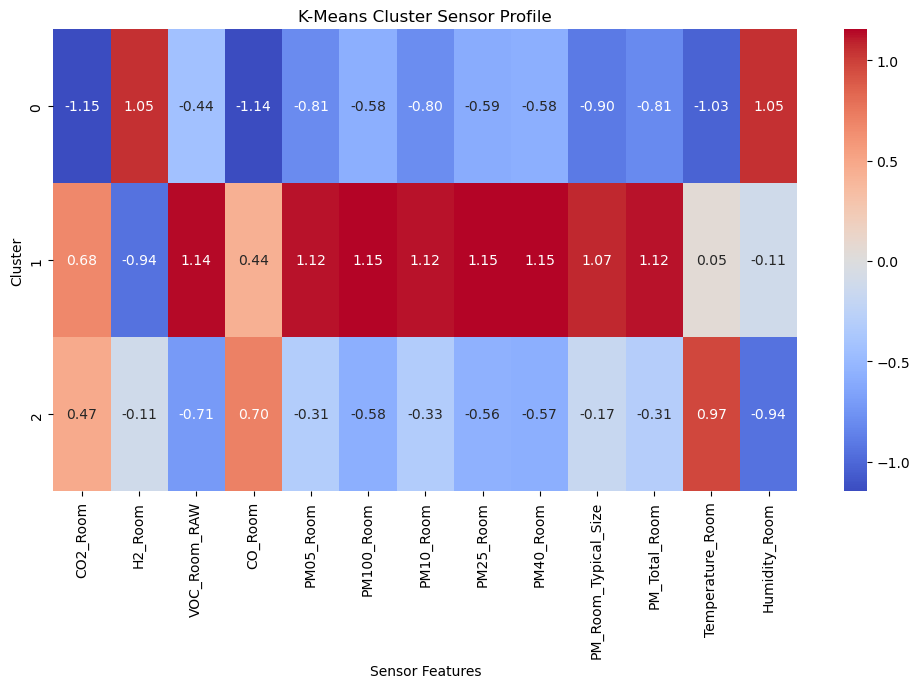

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

cluster_profile = df_transformed.groupby('cluster')[sensor_cols].mean()

# Normalize each feature for visualization
profile_normalized = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

plt.figure(figsize=(12, 6))

sns.heatmap(
    profile_normalized,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('K-Means Cluster Sensor Profile')
plt.xlabel('Sensor Features')
plt.ylabel('Cluster')

plt.show()

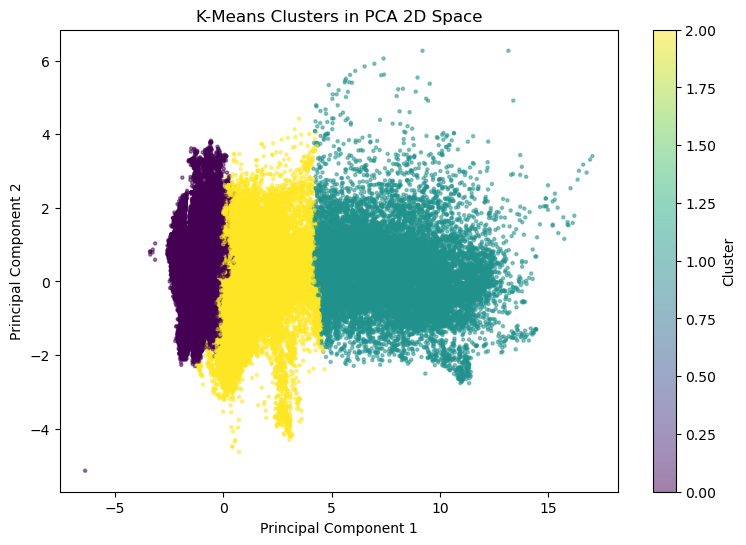

In [55]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df_transformed['cluster'],
    s=5,
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters in PCA 2D Space')
plt.colorbar(label='Cluster')

plt.show()

In [56]:
from sklearn.cluster import DBSCAN
import numpy as np

sample_indices = np.random.RandomState(42).choice(
    X_scaled.shape[0],
    size=10000,
    replace=False
)

X_dbscan = X_scaled[sample_indices]

In [57]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_dbscan)

print("Number of clusters:", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Number of noise points:", list(dbscan_labels).count(-1))

Number of clusters: 133
Number of noise points: 2657


In [58]:
eps_values = [0.3, 0.5, 0.7, 1.0, 1.5]

for eps in eps_values:
    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(X_dbscan)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    print(
        f"eps = {eps} → "
        f"Clusters = {n_clusters}, "
        f"Noise = {n_noise}"
    )

eps = 0.3 → Clusters = 167, Noise = 4826
eps = 0.5 → Clusters = 133, Noise = 2657
eps = 0.7 → Clusters = 46, Noise = 1457
eps = 1.0 → Clusters = 29, Noise = 688
eps = 1.5 → Clusters = 3, Noise = 160


In [59]:
dbscan_final = DBSCAN(
    eps=1.5,
    min_samples=5
)

dbscan_labels = dbscan_final.fit_predict(X_dbscan)

print("Number of clusters:", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Number of noise points:", list(dbscan_labels).count(-1))

Number of clusters: 3
Number of noise points: 160


In [60]:
import pandas as pd

dbscan_comparison = pd.crosstab(
    dbscan_labels,
    df_transformed.iloc[sample_indices]['anomaly_label']
)

print(dbscan_comparison)

anomaly_label   0.0   1.0
row_0                    
-1                1   159
 0             8335  1486
 1                0    15
 2                0     4


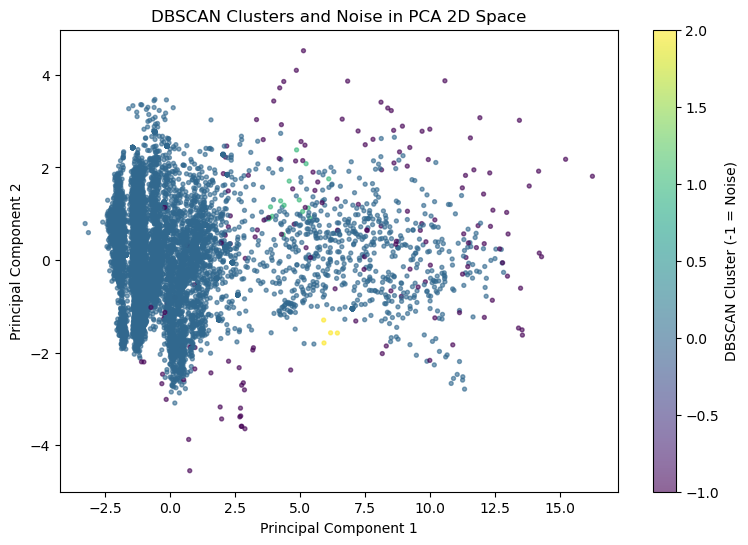

In [61]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_dbscan = PCA(n_components=2)
X_dbscan_pca = pca_dbscan.fit_transform(X_dbscan)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_dbscan_pca[:, 0],
    X_dbscan_pca[:, 1],
    c=dbscan_labels,
    s=8,
    alpha=0.6
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clusters and Noise in PCA 2D Space')
plt.colorbar(label='DBSCAN Cluster (-1 = Noise)')

plt.show()

In [62]:
from sklearn.metrics import silhouette_score

# Remove noise points
mask = dbscan_labels != -1

X_silhouette = X_dbscan[mask]
labels_silhouette = dbscan_labels[mask]

score = silhouette_score(
    X_silhouette,
    labels_silhouette
)

print(f"DBSCAN Silhouette Score = {score:.4f}")

DBSCAN Silhouette Score = 0.4446


In [63]:
from sklearn.cluster import AgglomerativeClustering
import numpy as np

sample_indices = np.random.RandomState(42).choice(
    X_scaled.shape[0],
    size=10000,
    replace=False
)

X_hierarchical = X_scaled[sample_indices]

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_hierarchical)

print("Number of clusters:", len(np.unique(hierarchical_labels)))

Number of clusters: 3


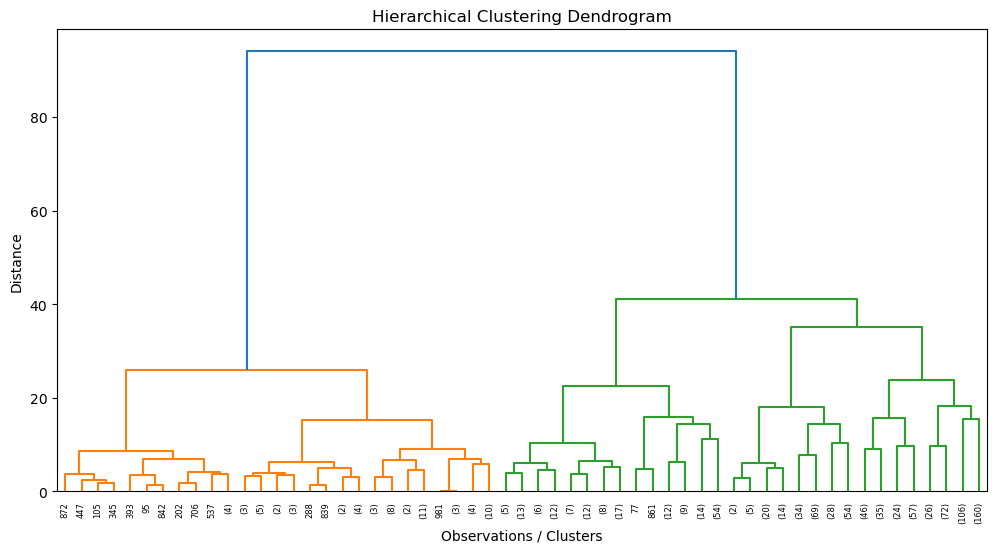

In [64]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

X_dendrogram = X_hierarchical[:1000]

Z = linkage(
    X_dendrogram,
    method='ward'
)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode='level',
    p=5
)

plt.xlabel('Observations / Clusters')
plt.ylabel('Distance')
plt.title('Hierarchical Clustering Dendrogram')

plt.show()

In [65]:
from sklearn.metrics import silhouette_score

hierarchical_silhouette = silhouette_score(
    X_hierarchical,
    hierarchical_labels
)

print(
    f"Hierarchical Silhouette Score = "
    f"{hierarchical_silhouette:.4f}"
)

Hierarchical Silhouette Score = 0.2669


In [66]:
# Add hierarchical cluster labels to the sampled data
hierarchical_df = df.iloc[sample_indices].copy()

hierarchical_df['cluster'] = hierarchical_labels

# Create cluster profile using original/raw sensor values
hierarchical_profile = hierarchical_df.groupby('cluster')[sensor_cols].mean()

print(hierarchical_profile.round(2))

         CO2_Room  H2_Room  VOC_Room_RAW  CO_Room  PM05_Room  PM100_Room  \
cluster                                                                    
0          644.00     1.43          1.26     0.26      18.78        0.00   
1          651.90     0.64          2.35     0.73    1854.14        0.32   
2          626.15     0.88          1.12     1.86      53.58        0.00   

         PM10_Room  PM25_Room  PM40_Room  PM_Room_Typical_Size  PM_Total_Room  \
cluster                                                                         
0             2.28       0.00       0.00                  0.46          21.63   
1           282.36      13.36       1.66                  0.51        2153.49   
2             8.09       0.30       0.03                  0.52          62.74   

         Temperature_Room  Humidity_Room  
cluster                                   
0                   28.32          43.37  
1                   29.60          41.21  
2                   29.65          40.98 

In [67]:
hierarchical_anomaly = pd.crosstab(
    hierarchical_df['cluster'],
    hierarchical_df['anomaly_label']
)

print(hierarchical_anomaly)

anomaly_label   0.0  1.0
cluster                 
0              6791  306
1                82  649
2              1463  709


In [68]:
hierarchical_anomaly_pct = pd.crosstab(
    hierarchical_df['cluster'],
    hierarchical_df['anomaly_label'],
    normalize='index'
) * 100

print(hierarchical_anomaly_pct.round(2))

anomaly_label    0.0    1.0
cluster                    
0              95.69   4.31
1              11.22  88.78
2              67.36  32.64
